In [10]:

import tensorflow as tf
import matplotlib.pyplot as plt
import time
import pandas as pd

# Load CIFAR-10 dataset
(X_train, y_train), (X_test, y_test) = tf.keras.datasets.cifar10.load_data()

# Normalize images
X_train = X_train.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

# Class names
classes = ["Airplane", "Car", "Bird", "Cat", "Deer",
           "Dog", "Frog", "Horse", "Ship", "Truck"]

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)


Training data: (50000, 32, 32, 3)
Testing data: (10000, 32, 32, 3)


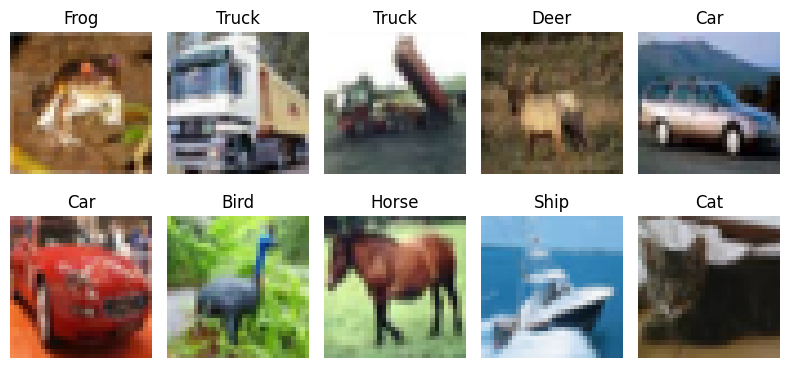

In [12]:
#Display sample images
plt.figure(figsize=(8, 4))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_train[i])
    plt.title(classes[int(y_train[i][0])])
    plt.axis("off")

plt.tight_layout()
plt.show()


In [13]:
#Create the MLP model
mlp = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(32, 32, 3)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(512, activation="relu"),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Dense(256, activation="relu"),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Dense(10, activation="softmax")
])

mlp.compile(optimizer="adam",
            loss="sparse_categorical_crossentropy",
            metrics=["accuracy"])

mlp.summary()


Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ flatten_4 (Flatten)                  │ (None, 3072)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_10 (Dense)                     │ (None, 512)                 │       1,573,376 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_6 (Dropout)                  │ (None, 512)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_11 (Dense)                     │ (None, 256)                 │         131,328 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_7 (Dropout)                  │ (None, 256)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_12 (Dense)                     │ (None, 10)                  │           2,570 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 1,707,274 (6.51 MB)

 Trainable params: 1,707,274 (6.51 MB)

 Non-trainable params: 0 (0.00 B)

In [14]:
#Train both models
cnn = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(32, 32, 3)),

    # Data augmentation
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.1),
    tf.keras.layers.RandomZoom(0.1),

    # Convolution and pooling
    tf.keras.layers.Conv2D(32, 3, padding="same", activation="relu"),
    tf.keras.layers.MaxPooling2D(2),
    tf.keras.layers.Conv2D(64, 3, padding="same", activation="relu"),
    tf.keras.layers.MaxPooling2D(2),

    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dropout(0.4),
    tf.keras.layers.Dense(10, activation="softmax")
])

cnn.compile(optimizer="adam",
            loss="sparse_categorical_crossentropy",
            metrics=["accuracy"])


In [15]:
#Evaluate and compare models
mlp_loss, mlp_acc = mlp.evaluate(X_test, y_test, verbose=0)
cnn_loss, cnn_acc = cnn.evaluate(X_test, y_test, verbose=0)

results = pd.DataFrame({
    "Measure": ["Test Accuracy (%)", "Test Loss", "Training Time (seconds)"],
    "MLP": [round(mlp_acc*100, 2), round(mlp_loss, 4),
            round(mlp_time, 2)],
    "CNN": [round(cnn_acc*100, 2), round(cnn_loss, 4),
            round(cnn_time, 2)]
})

display(results)


NameError: name 'mlp_time' is not defined

In [ ]:
#Plot accuracy and loss
# Accuracy graph
plt.figure(figsize=(8, 4))

for h, name in [(h_mlp, "MLP"), (h_cnn, "CNN")]:
    plt.plot(h.history["accuracy"], label=name + " Training")
    plt.plot(h.history["val_accuracy"], "--", label=name + " Validation")

plt.title("Accuracy Comparison")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

# Loss graph
plt.figure(figsize=(8, 4))

for h, name in [(h_mlp, "MLP"), (h_cnn, "CNN")]:
    plt.plot(h.history["loss"], label=name + " Training")
    plt.plot(h.history["val_loss"], "--", label=name + " Validation")

plt.title("Loss Comparison")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()


In [ ]:
#Display 10 CNN predictions
predictions = cnn.predict(X_test[:10], verbose=0)

plt.figure(figsize=(10, 5))

for i in range(10):
    actual = classes[y_test[i]]
    predicted = classes[np.argmax(predictions[i])]

    plt.subplot(2, 5, i + 1)
    plt.imshow(X_test[i])
    plt.title(f"Actual: {actual}\nPredicted: {predicted}", fontsize=8)
    plt.axis("off")

plt.tight_layout()
plt.show()
